# Predicting Hard-Drive Failures Before They Happen
### Mini-project — Predictive Analytics

**Dataset:** Backblaze hard-drive statistics, Q1 2026 — one row per drive per day (90 days, ~340,000 drives/day,
~30 million rows) with the drive's model, a `failure` flag, and its **SMART** self-monitoring counters.

**Goal:** detect the *early warning signs* that a drive is about to fail, and recommend an action
(back up / replace / fix cabling / cool) **before** the failure happens.

| Type of analytics | Question it answers in this project | Section |
|---|---|---|
| **Descriptive** | How many drives fail, which models fail most? | 3–4, 11 |
| **Predictive** | Will *this* drive fail within the next 7 days? How many drives will fail next week? | 7–10, 12 |
| **Prescriptive** | What should the operator do about it? | 13 |

**Why it matters (industry role):** in IT / cloud data centres, a failed disk means downtime, a RAID rebuild and
risk of data loss. Replacing a drive *proactively* is far cheaper than recovering from a surprise failure.
The same pattern (sensor readings → risk score → maintenance action) is used for aircraft engines, wind
turbines and medical devices (*predictive maintenance*).

**Ethical considerations:** the data contains no personal information (drives are identified only by serial).
The main ethical risks are operational: a model that misses failures (false negatives) gives a false sense of
safety, and one that raises too many alarms wastes hardware and erodes trust. We therefore report recall and
precision explicitly and keep the model interpretable (logistic regression) so every alert can be explained.

## 1. Data collection and real-world challenges

The raw data is 90 CSV files, ~11 GB — too big for memory. `prepare_data.py` reduces it once:

* **Daily totals** (drives running, failures) → time-series forecasting.
* **Per-model totals** (drive-days, failures) → Poisson / Negative-Binomial count regression.
* **SMART history** of **every drive that failed** (1,030 drives) plus a **random 3 % sample of drives that did not**
  → classification models.

Challenges we hit in this real dataset:

1. **Extreme class imbalance** — ~11 failures/day out of ~340,000 drives (0.003 %).
2. **Missing values** — different vendors report different SMART attributes (e.g. attribute 187/188 only on Seagate).
3. **Vendor-specific encodings** — Seagate packs three counters into the raw value of attribute 188, giving absurd numbers.
4. **Censoring** — a drive that is healthy on 31 March may fail in April; we cannot see that.
5. **Outliers** — but in this problem many "outliers" (huge error counts) *are the signal*, so they must not be blindly removed.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.feature_selection import f_classif
from sklearn.metrics import (f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix,
                             classification_report, precision_recall_curve, ConfusionMatrixDisplay,
                             mean_squared_error, mean_absolute_error)
import os; os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_parquet("data/drive_days.parquet")
df["date"] = pd.to_datetime(df["date"]); df["failure_date"] = pd.to_datetime(df["failure_date"])
print(f"{len(df):,} drive-day rows | {df.serial_number.nunique():,} drives | "
      f"{df.failure_date.notna().groupby(df.serial_number).any().sum():,} of them failed")
df.head()

951,642 drive-day rows | 11,445 drives | 1,030 of them failed


,date,serial_number,model,capacity_bytes,failure,reallocated_sectors,reported_uncorrectable,command_timeout,pending_sectors,offline_uncorrectable,crc_errors,power_on_hours,power_cycles,load_cycles,temperature_c,failure_date
0,2026-01-01,06c543f293e20010,DELLBOSS VD,480036847616,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT
1,2026-01-01,1030A00MF9RG,TOSHIBA MG07ACA14TEY,14000519643136,0,0.000,NaN,NaN,NaN,0.000,0.000,"15,173.000",13.000,16.000,30.000,NaT
2,2026-01-01,1030A063F97G,TOSHIBA MG07ACA14TA,14000519643136,0,0.000,NaN,NaN,0.000,0.000,0.000,"43,622.000",11.000,19.000,34.000,NaT
3,2026-01-01,1040A002F9RG,TOSHIBA MG07ACA14TEY,14000519643136,0,0.000,NaN,NaN,NaN,0.000,0.000,"44,852.000",34.000,497.000,27.000,NaT
4,2026-01-01,1040A026F97G,TOSHIBA MG07ACA14TA,14000519643136,0,0.000,NaN,NaN,0.000,0.000,0.000,"41,782.000",8.000,14.000,37.000,NaT


### 1.1 Defining the target — "failure is about to happen"

For each drive-day we compute `days_to_failure`. The **binary target** is
`fail_7d = 1` if the drive fails within the next 7 days (days_to_failure 0–6).
For the multinomial model we also define three **risk tiers**:

| tier | meaning |
|---|---|
| 0 – Healthy | no failure within 30 days |
| 1 – Degrading | failure in 7–29 days |
| 2 – Imminent | failure within 7 days |

To handle **censoring**, rows from the last 7 days of the quarter are dropped from the modelling set (we can't yet
know if those drives fail within 7 days).

In [2]:
df["days_to_failure"] = (df["failure_date"] - df["date"]).dt.days
df["fail_7d"] = df["days_to_failure"].between(0, 6).astype(int)
df["risk_tier"] = np.select([df["days_to_failure"].between(0, 6), df["days_to_failure"].between(7, 29)], [2, 1], 0)
cutoff = df["date"].max() - pd.Timedelta(days=7)
print("modelling rows end at", cutoff.date())
print(df.loc[df.date <= cutoff, "fail_7d"].value_counts().rename({0: "no failure in 7d", 1: "fails within 7d"}))

modelling rows end at 2026-03-24
fail_7d
no failure in 7d    873687
fails within 7d       5837
Name: count, dtype: int64


## 2. Data preprocessing — cleaning, missing values, outliers

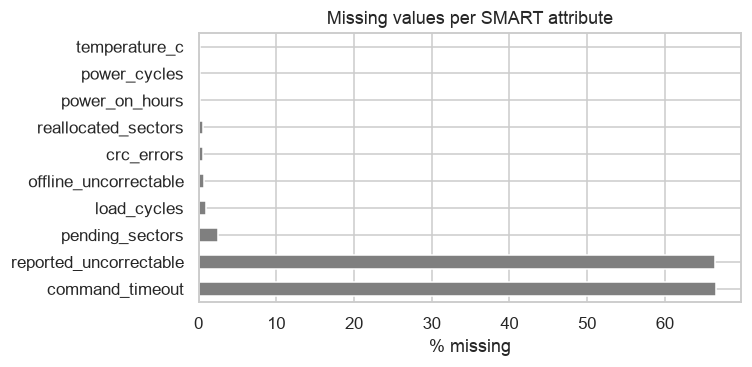

In [3]:
smart_cols = ["reallocated_sectors", "reported_uncorrectable", "command_timeout", "pending_sectors",
              "offline_uncorrectable", "crc_errors", "power_on_hours", "power_cycles", "load_cycles", "temperature_c"]
miss = df[smart_cols].isna().mean().mul(100).sort_values(ascending=False)
ax = miss.plot.barh(figsize=(7, 3.5), color="tab:gray"); ax.set_xlabel("% missing"); ax.set_title("Missing values per SMART attribute")
plt.tight_layout(); plt.savefig("figures/01_missing.png"); plt.show()

def maker(m):
    m = m.upper()
    if m.startswith(("ST", "SEAGATE")): return "Seagate"
    for k in ["TOSHIBA", "WDC", "HGST"]:
        if m.startswith(k): return {"WDC": "WDC", "HGST": "HGST", "TOSHIBA": "Toshiba"}[k]
    return "Other"
df["manufacturer"] = df["model"].map(maker)

**Missing-value strategy**

* Attributes 187/188 are *not reported* by Toshiba/WDC/HGST drives — the value isn't unknown, the counter simply
  doesn't exist. We fill with **0** (no errors reported). Attribute 188 is turned into a **0/1 flag** because
  Seagate's raw value is bit-packed and not a real count.
* Error counters with a few missing days (< 3 %) → filled with the **same drive's previous reading** (forward fill), then 0.
* Age / temperature (< 0.2 % missing) → **median imputation**.

In [4]:
df = df.sort_values(["serial_number", "date"]).reset_index(drop=True)
err_cols = ["reallocated_sectors", "reported_uncorrectable", "pending_sectors", "offline_uncorrectable", "crc_errors"]
df[err_cols] = df.groupby("serial_number")[err_cols].ffill().fillna(0)
df["command_timeout_flag"] = (df["command_timeout"].fillna(0) > 0).astype(int)
for c in ["power_on_hours", "power_cycles", "load_cycles", "temperature_c"]:
    df[c] = df[c].fillna(df[c].median())
print("remaining missing values:", int(df[err_cols + ["power_on_hours", "temperature_c"]].isna().sum().sum()))

remaining missing values: 0


### 2.1 Outliers — IQR rule and box plots

IQR rule: a value is an outlier if it is below $Q_1 - 1.5\,IQR$ or above $Q_3 + 1.5\,IQR$, where $IQR = Q_3 - Q_1$.

In [5]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for c in ["temperature_c", "power_on_hours", "power_cycles", "reallocated_sectors", "pending_sectors"]:
    lo, hi = iqr_bounds(df[c]); out = ~df[c].between(lo, hi)
    rows.append([c, lo, hi, out.mean() * 100, df.loc[out, "fail_7d"].mean() * 100, df.loc[~out, "fail_7d"].mean() * 100])
pd.DataFrame(rows, columns=["attribute", "lower", "upper", "% outliers", "% failing (outliers)", "% failing (normal)"])

,attribute,lower,upper,% outliers,% failing (outliers),% failing (normal)
0,temperature_c,19.500,47.500,0.414,1.344,0.641
1,power_on_hours,"-30,114.500","91,337.500",0.018,0.000,0.644
2,power_cycles,-4.000,28.000,6.334,1.029,0.618
3,reallocated_sectors,0.000,0.000,7.402,5.241,0.276
4,pending_sectors,0.000,0.000,3.921,8.982,0.303


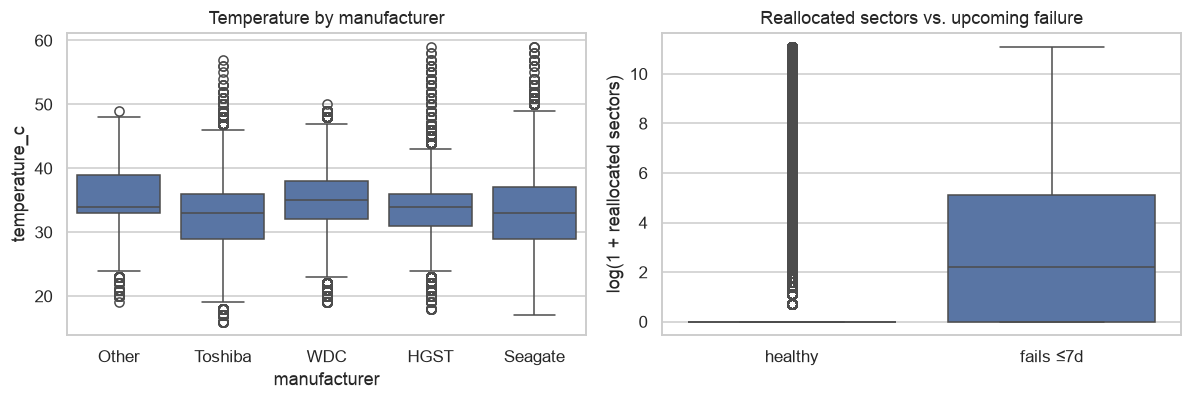

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(data=df, x="manufacturer", y="temperature_c", ax=axes[0]); axes[0].set_title("Temperature by manufacturer")
sns.boxplot(x=df["fail_7d"].map({0: "healthy", 1: "fails ≤7d"}), y=np.log1p(df["reallocated_sectors"]), ax=axes[1])
axes[1].set_ylabel("log(1 + reallocated sectors)"); axes[1].set_xlabel(""); axes[1].set_title("Reallocated sectors vs. upcoming failure")
plt.tight_layout(); plt.savefig("figures/02_boxplots.png"); plt.show()

**Decision.** For *temperature*, *age* and *power cycles*, outliers are mostly measurement quirks (a few drives report
>1,000 power cycles vs. a median of 12; left uncapped, a linear model extrapolates these to a risk of ~100 %) → we **cap** them at the IQR fences
(winsorising). For the *error counters*, almost every non-zero value is an "outlier" by the IQR rule (the median is 0),
yet drives with outlying error counts are **far more likely to fail** (table above). Removing them would delete the
very signal we want. Instead we keep them and tame their scale with a `log(1+x)` transform (Section 5).

In [7]:
for c in ["temperature_c", "power_on_hours", "power_cycles"]:
    lo, hi = iqr_bounds(df[c]); df[c] = df[c].clip(lo, hi)

## 3. Exploratory Data Analysis — central tendency, spread, Z-scores

In [8]:
num = ["reallocated_sectors", "pending_sectors", "offline_uncorrectable", "reported_uncorrectable", "crc_errors",
       "power_on_hours", "temperature_c"]
stats = df[num].agg(["mean", "median", "var", "std"]).T
stats["mode"] = df[num].mode().iloc[0]
stats[["mean", "median", "mode", "var", "std"]]

,mean,median,mode,var,std
reallocated_sectors,126.556,0.000,0.000,"4,001,746.243","2,000.437"
pending_sectors,55.839,0.000,0.000,"11,340,474.945","3,367.562"
offline_uncorrectable,50.554,0.000,0.000,"11,306,203.825","3,362.470"
reported_uncorrectable,5.471,0.000,0.000,"123,260.886",351.085
crc_errors,1.732,0.000,0.000,"2,141.317",46.274
power_on_hours,"31,358.312","30,848.000","30,848.000","361,033,885.114","19,000.892"
temperature_c,33.485,34.000,34.000,25.023,5.002


In [9]:
# Same statistics split by outcome: drives about to fail vs. healthy drives
df.groupby(df["fail_7d"].map({0: "healthy", 1: "fails ≤7d"}))[num].agg(["mean", "median"]).T.unstack()

fail_7d                 fails ≤7d               healthy           
                             mean     median       mean     median
reallocated_sectors     2,131.063      8.000    113.571      0.000
pending_sectors         3,051.112      2.000     36.436      0.000
offline_uncorrectable   2,921.078      0.000     31.959      0.000
reported_uncorrectable    179.727      0.000      4.342      0.000
crc_errors                  0.376      0.000      1.741      0.000
power_on_hours         36,148.859 40,012.000 31,327.279 30,830.000
temperature_c              33.712     34.000     33.484     34.000

**Reading the numbers.** For error counters, mean ≫ median = 0 → strongly **right-skewed** distributions (most drives
have no errors, a few have thousands). The mean reallocated-sector count of drives about to fail is orders of magnitude
higher than for healthy drives — the first evidence of predictive power.

**Z-score** $z = (x - \mu)/\sigma$ tells how many standard deviations a reading is from the fleet average.

In [10]:
df["z_reallocated_sectors"] = (df["reallocated_sectors"] - df["reallocated_sectors"].mean()) / df["reallocated_sectors"].std()
print(f"rows with |z| > 3: {(df.z_reallocated_sectors.abs() > 3).mean():.2%}")
print("failure-within-7-days rate, |z| > 3 vs ≤ 3:")
print(df.groupby(df["z_reallocated_sectors"].abs() > 3)["fail_7d"].mean().round(4))

rows with |z| > 3: 0.43%
failure-within-7-days rate, |z| > 3 vs ≤ 3:
z_reallocated_sectors
False   0.006
True    0.116
Name: fail_7d, dtype: float64


## 4. Data visualisation

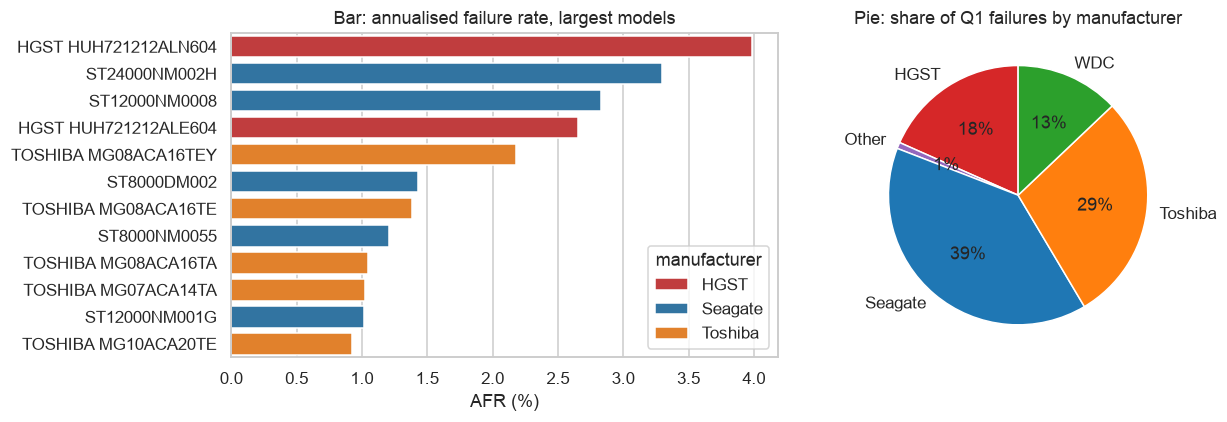

In [11]:
mc = pd.read_csv("data/model_counts.csv")
mc["manufacturer"] = mc["model"].map(maker)
mc["AFR_%"] = mc["failures"] / mc["drive_days"] * 365 * 100   # annualised failure rate

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = mc[mc.drive_days > 300_000].sort_values("AFR_%", ascending=False).head(12)
MFR_COLORS = dict(zip(["Seagate", "Toshiba", "WDC", "HGST", "Other"], sns.color_palette("tab10", 5)))
sns.barplot(data=top, y="model", x="AFR_%", hue="manufacturer", palette=MFR_COLORS, dodge=False, ax=axes[0])
axes[0].set_title("Bar: annualised failure rate, largest models"); axes[0].set_xlabel("AFR (%)"); axes[0].set_ylabel("")
fails = mc.groupby("manufacturer")["failures"].sum()
axes[1].pie(fails, labels=fails.index, colors=[MFR_COLORS[m] for m in fails.index], autopct="%1.0f%%", startangle=90); axes[1].set_title("Pie: share of Q1 failures by manufacturer")
plt.tight_layout(); plt.savefig("figures/03_bar_pie.png"); plt.show()

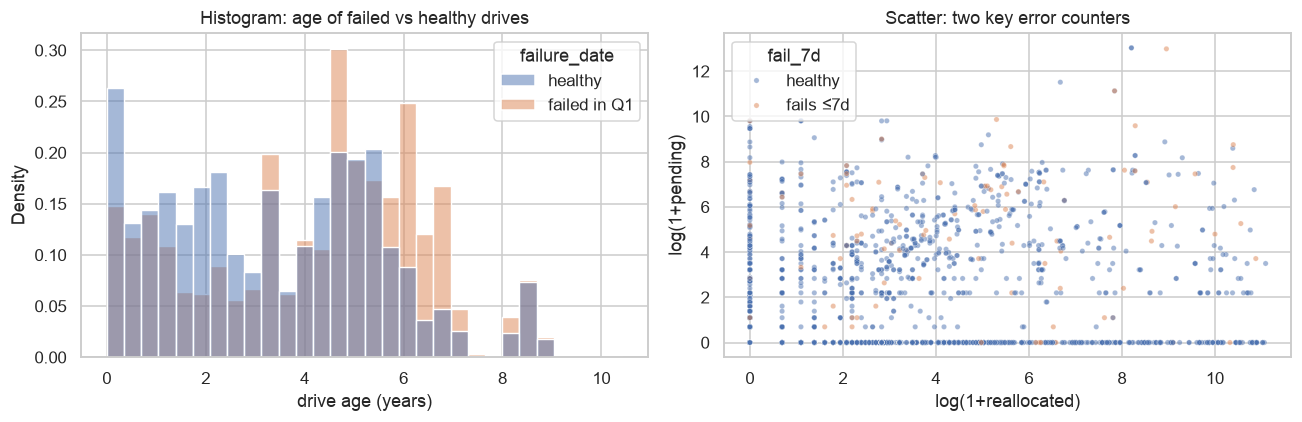

In [12]:
first = df.drop_duplicates("serial_number")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=first, x=first["power_on_hours"] / 8760, hue=first["failure_date"].notna().map({True: "failed in Q1", False: "healthy"}),
             stat="density", common_norm=False, bins=30, ax=axes[0])
axes[0].set_xlabel("drive age (years)"); axes[0].set_title("Histogram: age of failed vs healthy drives")
s = df.sample(30_000, random_state=1)
sns.scatterplot(x=np.log1p(s.reallocated_sectors), y=np.log1p(s.pending_sectors), hue=s.fail_7d.map({0: "healthy", 1: "fails ≤7d"}),
                alpha=.5, s=12, ax=axes[1])
axes[1].set_xlabel("log(1+reallocated)"); axes[1].set_ylabel("log(1+pending)"); axes[1].set_title("Scatter: two key error counters")
plt.tight_layout(); plt.savefig("figures/04_hist_scatter.png"); plt.show()

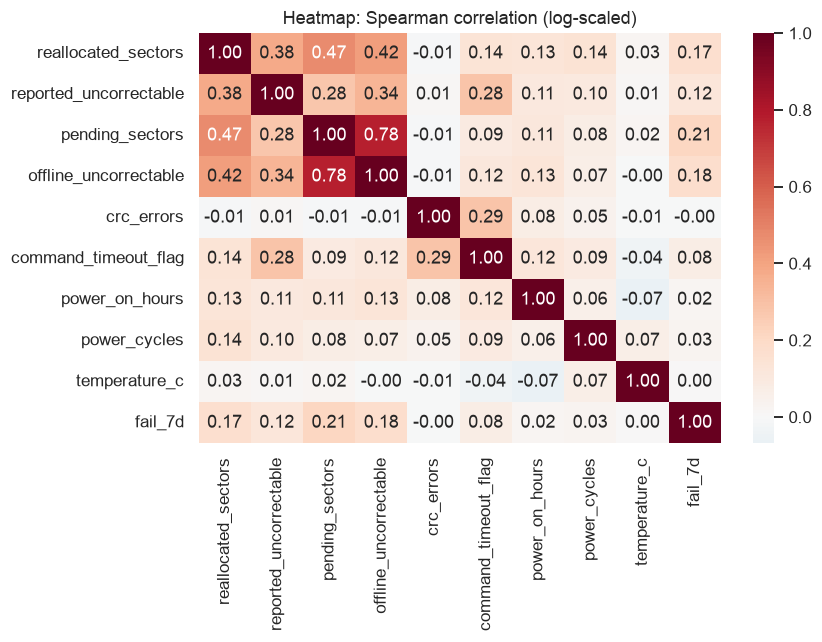

In [13]:
corr_cols = err_cols + ["command_timeout_flag", "power_on_hours", "power_cycles", "temperature_c", "fail_7d"]
plt.figure(figsize=(8, 6))
sns.heatmap(np.log1p(df[corr_cols].clip(lower=0)).corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Heatmap: Spearman correlation (log-scaled)"); plt.tight_layout(); plt.savefig("figures/05_heatmap.png"); plt.show()

## 5. Feature engineering

Raw counters tell *how bad* a drive is; failures are better predicted by *how fast it is getting worse*.

| new feature | idea |
|---|---|
| `log_*` | `log(1+x)` of every error counter — removes skew, keeps outliers |
| `bad_sectors` | reallocated + pending + offline-uncorrectable |
| `bad_sector_growth_7d` | increase in bad sectors over the last 7 days (**trend**) |
| `any_critical_error` | 1 if any of SMART 5/187/197/198 > 0 (Backblaze's rule of thumb) |
| `age_years` | power-on hours / 8760 |
| `capacity_tb`, manufacturer dummies | drive family effects |

In [14]:
for c in err_cols:
    df[f"log_{c}"] = np.log1p(df[c].clip(lower=0))
df["bad_sectors"] = df[["reallocated_sectors", "pending_sectors", "offline_uncorrectable"]].sum(axis=1)
df["bad_sector_growth_7d"] = df.groupby("serial_number")["bad_sectors"].diff(7).fillna(0).clip(lower=0)
df["log_bad_sector_growth_7d"] = np.log1p(df["bad_sector_growth_7d"])
df["any_critical_error"] = (df[["reallocated_sectors", "reported_uncorrectable", "pending_sectors", "offline_uncorrectable"]].sum(axis=1) > 0).astype(int)
df["age_years"] = df["power_on_hours"] / 8760
df["capacity_tb"] = (df["capacity_bytes"] / 1e12).round()
df = pd.concat([df, pd.get_dummies(df["manufacturer"], prefix="mfr", drop_first=True, dtype=int)], axis=1)

candidates = [f"log_{c}" for c in err_cols] + ["log_bad_sector_growth_7d", "any_critical_error", "command_timeout_flag",
              "age_years", "temperature_c", "power_cycles", "capacity_tb"] + [c for c in df if c.startswith("mfr_")]
model_df = df[df.date <= cutoff].copy()
print(len(candidates), "candidate features;", f"{len(model_df):,} modelling rows; positives = {model_df.fail_7d.sum():,}")

16 candidate features; 879,524 modelling rows; positives = 5,837


## 6. Feature selection

Two methods: the **ANOVA F-test** (filter method: do failing and healthy rows differ on this feature?) and an
**L1-penalised logistic regression** (embedded method), which shrinks useless coefficients towards zero. A feature is kept only if it passes **both** the ANOVA test (p < 0.001)
and keeps an L1 coefficient of at least 0.05 — i.e. it is related to failure *and* adds information the other
features don't already carry (redundant, correlated counters get shrunk away).

In [15]:
X_all, y_all = model_df[candidates].astype(float), model_df["fail_7d"]
F, F_p = f_classif(X_all, y_all)
l1 = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", C=0.01, solver="liblinear", class_weight="balanced")).fit(X_all, y_all)
sel = pd.DataFrame({"ANOVA_F": F, "ANOVA_p": F_p, "L1_coef": l1[-1].coef_[0]}, index=candidates).sort_values("ANOVA_F", ascending=False)
sel

,ANOVA_F,ANOVA_p,L1_coef
log_pending_sectors,"54,634.864",0.000,0.279
log_bad_sector_growth_7d,"44,989.102",0.000,0.140
log_offline_uncorrectable,"40,322.256",0.000,-0.065
log_reallocated_sectors,"30,500.554",0.000,0.000
any_critical_error,"28,277.685",0.000,0.719
log_reported_uncorrectable,"22,265.195",0.000,0.099
command_timeout_flag,"5,801.536",0.000,0.029
power_cycles,662.351,0.000,0.210
age_years,358.294,0.000,0.213
mfr_WDC,331.918,0.000,-0.562


In [16]:
# rule: significant in the ANOVA test AND a non-negligible coefficient after L1 shrinkage
features = [f for f in sel.index if sel.loc[f, "ANOVA_p"] < 0.001 and abs(sel.loc[f, "L1_coef"]) >= 0.05]
print("dropped:", [f for f in candidates if f not in features])
print(f"kept {len(features)} / {len(candidates)} features:", features)

dropped: ['log_reallocated_sectors', 'log_crc_errors', 'command_timeout_flag', 'temperature_c', 'mfr_Other']
kept 11 / 16 features: ['log_pending_sectors', 'log_bad_sector_growth_7d', 'log_offline_uncorrectable', 'any_critical_error', 'log_reported_uncorrectable', 'power_cycles', 'age_years', 'mfr_WDC', 'capacity_tb', 'mfr_Seagate', 'mfr_Toshiba']


## 7. Train-test split and cross-validation

Rows of the same drive are highly correlated (day *t* looks like day *t+1*). A random row split would put the same drive
in both train and test and inflate scores (**data leakage**). We therefore split **by drive** (`GroupShuffleSplit`,
75 / 25) and use **5-fold `GroupKFold`** cross-validation on the training part.

In [17]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr_idx, te_idx = next(gss.split(model_df, groups=model_df["serial_number"]))
train, test = model_df.iloc[tr_idx], model_df.iloc[te_idx]
X_tr, y_tr, g_tr = train[features].astype(float), train["fail_7d"], train["serial_number"]
X_te, y_te = test[features].astype(float), test["fail_7d"]
print(f"train: {len(train):,} rows / {g_tr.nunique():,} drives / {y_tr.sum():,} positives")
print(f"test : {len(test):,} rows / {test.serial_number.nunique():,} drives / {y_te.sum():,} positives")
cv = GroupKFold(n_splits=5)

train: 659,624 rows / 8,515 drives / 4,260 positives
test : 219,900 rows / 2,839 drives / 1,577 positives


## 8. Logistic regression — binary classification "fails within 7 days?"

$$P(\text{fail}_{7d}=1 \mid x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$$

Because only ~1 % of rows are positive, we use `class_weight="balanced"` so the model doesn't just predict "healthy" for
everything. The decision threshold is then tuned on **cross-validated** training predictions to maximise F1 —
the test set is never touched while tuning.

In [18]:
logit = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))

def tune_threshold(model):
    # threshold that maximises F1 on out-of-fold (cross-validated) training predictions
    oof = cross_val_predict(model, X_tr, y_tr, groups=g_tr, cv=cv, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_tr, oof)
    f1s = 2 * p * r / (p + r + 1e-12)
    return t[np.argmax(f1s[:-1])], f1s[:-1].max()

best_t, cv_best = tune_threshold(logit)
print(f"best threshold from CV = {best_t:.3f}  (CV F1 = {cv_best:.3f})")
logit.fit(X_tr, y_tr);

best threshold from CV = 0.959  (CV F1 = 0.218)


### 8.1 Estimating the regression coefficients (maximum likelihood)

`statsmodels` fits the same model by **maximum likelihood (Newton-Raphson / IRLS)** and gives standard errors and
p-values. $e^{\beta}$ is the **odds ratio**: how much the odds of failing within 7 days multiply when the feature rises
by one unit (here: one standard deviation, since features are standardised). Fit on all positives + a 60 k sample of
negatives for speed.

In [19]:
sub = pd.concat([train[train.fail_7d == 1], train[train.fail_7d == 0].sample(60_000, random_state=0)])
Z = (sub[features] - X_tr.mean()) / X_tr.std()
sm_logit = sm.Logit(sub["fail_7d"], sm.add_constant(Z)).fit(disp=0)
coef = pd.DataFrame({"coef β": sm_logit.params, "std err": sm_logit.bse, "p-value": sm_logit.pvalues,
                     "odds ratio e^β": np.exp(sm_logit.params)}).drop("const").sort_values("odds ratio e^β", ascending=False)
print(f"McFadden pseudo-R² = {sm_logit.prsquared:.3f}")
coef

McFadden pseudo-R² = 0.368


,coef β,std err,p-value,odds ratio e^β
any_critical_error,0.761,0.016,0.000,2.140
capacity_tb,0.695,0.034,0.000,2.003
log_pending_sectors,0.197,0.013,0.000,1.218
power_cycles,0.133,0.020,0.000,1.142
age_years,0.131,0.029,0.000,1.140
log_bad_sector_growth_7d,0.127,0.008,0.000,1.136
log_reported_uncorrectable,0.121,0.009,0.000,1.129
log_offline_uncorrectable,-0.044,0.012,0.000,0.957
mfr_Toshiba,-0.213,0.034,0.000,0.809
mfr_Seagate,-0.269,0.035,0.000,0.764


## 9. Discriminant analysis — LDA and QDA

Discriminant analysis models each class as a multivariate normal distribution and uses Bayes' rule.

* **LDA** – classes share one covariance matrix → *linear* boundary.
* **QDA** – each class has its own covariance matrix → *quadratic* boundary, more flexible but needs more data.

We set equal priors `[0.5, 0.5]` (the analogue of `class_weight="balanced"`), and — for a fair comparison — every model
gets its own F1-optimal threshold tuned by cross-validation on the training set.

In [20]:
models = {
    "Logistic regression": logit,
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(priors=[.5, .5])),
    "QDA": make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(priors=[.5, .5], reg_param=0.05)),
}
rows, probs, thresholds = [], {}, {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pr = m.predict_proba(X_te)[:, 1]; probs[name] = pr
    thr = best_t if name == "Logistic regression" else tune_threshold(m)[0]
    thresholds[name] = thr
    yhat = (pr >= thr).astype(int)
    rows.append([name, thr, precision_score(y_te, yhat), recall_score(y_te, yhat), f1_score(y_te, yhat), roc_auc_score(y_te, pr)])
results = pd.DataFrame(rows, columns=["model", "threshold", "precision", "recall", "F1", "ROC-AUC"]).set_index("model")
results

,threshold,precision,recall,F1,ROC-AUC
model,,,,,
Logistic regression,0.959,0.222,0.268,0.243,0.870
LDA,1.000,0.204,0.257,0.227,0.867
QDA,1.000,0.167,0.392,0.234,0.869


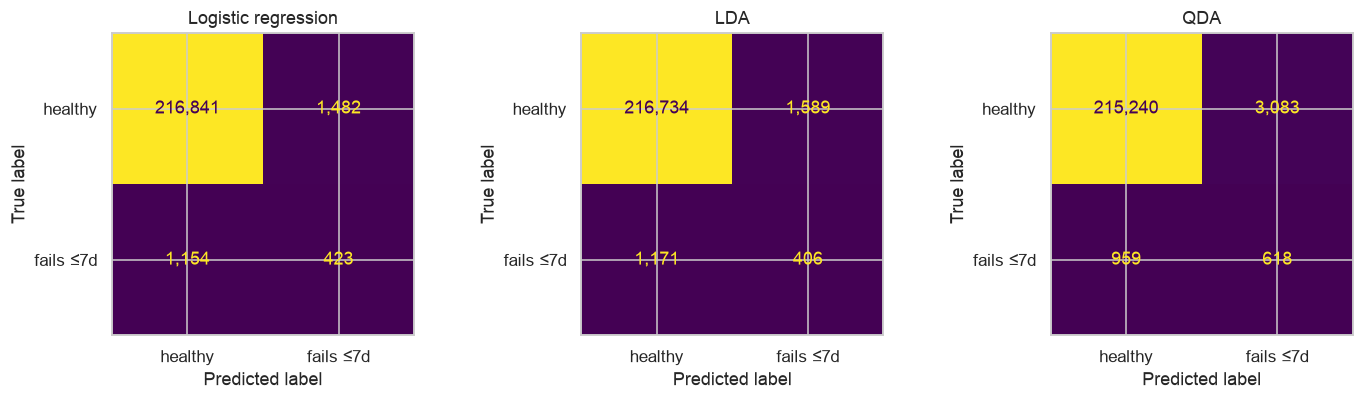

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, pr) in zip(axes, probs.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pr >= thresholds[name]), display_labels=["healthy", "fails ≤7d"]).plot(ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout(); plt.savefig("figures/06_confusion.png"); plt.show()

## 10. Multinomial logistic regression — three risk tiers

Instead of yes/no, predict **Healthy / Degrading (7–29 days) / Imminent (< 7 days)**. Multinomial logistic
regression fits one linear score per class and turns them into probabilities with the **softmax** function.

              precision    recall  f1-score   support

     Healthy      0.992     0.902     0.945    213670
   Degrading      0.094     0.440     0.155      4653
    Imminent      0.147     0.370     0.210      1577

    accuracy                          0.888    219900
   macro avg      0.411     0.570     0.437    219900
weighted avg      0.967     0.888     0.923    219900



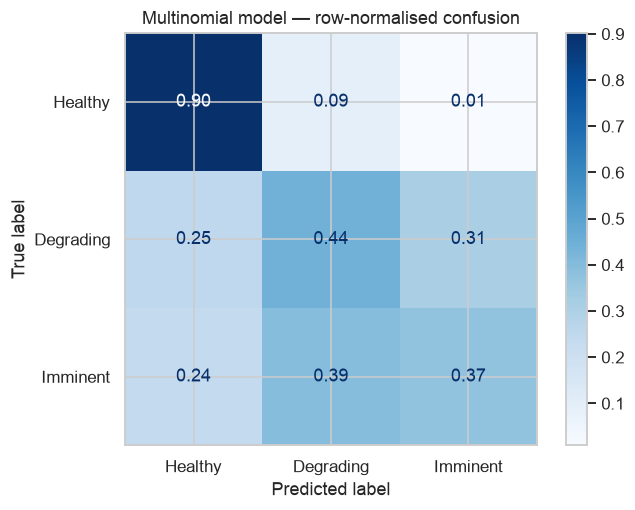

In [22]:
yt_tr, yt_te = train["risk_tier"], test["risk_tier"]
mlogit = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)).fit(X_tr, yt_tr)
pred_tier = mlogit.predict(X_te)
print(classification_report(yt_te, pred_tier, target_names=["Healthy", "Degrading", "Imminent"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(yt_te, pred_tier, normalize="true"), display_labels=["Healthy", "Degrading", "Imminent"]).plot(cmap="Blues", values_format=".2f")
plt.title("Multinomial model — row-normalised confusion"); plt.tight_layout(); plt.savefig("figures/07_multinomial.png"); plt.show()

## 11. Generalised Linear Models for counts — Poisson and Negative Binomial regression

Now the unit is a **drive model**, the response is the **number of failures** in Q1, and exposure is the number of
**drive-days**. A GLM with log link:

$$\log E[\text{failures}] = \log(\text{drive\_days}) + \beta_0 + \beta_1\,\text{age} + \beta_2\,\text{capacity} + \beta_{mfr}$$

`log(drive_days)` is an **offset** (coefficient fixed to 1), so the model describes the failure *rate*.
Poisson assumes variance = mean; if the data are **over-dispersed** (variance > mean) the Negative Binomial,
which adds a dispersion parameter α, is more appropriate.

In [23]:
age_by_model = df.groupby("model").agg(age_years=("age_years", "mean"), capacity_tb=("capacity_tb", "first"))
glm_df = mc.merge(age_by_model, left_on="model", right_index=True)
glm_df = glm_df[glm_df.drive_days >= 9_000].copy()          # models with ≥ ~100 drives
glm_df["log_exposure"] = np.log(glm_df["drive_days"])
print(f"{len(glm_df)} drive models")

formula = "failures ~ age_years + capacity_tb + C(manufacturer)"
pois = smf.glm(formula, data=glm_df, family=sm.families.Poisson(), offset=glm_df["log_exposure"]).fit()
dispersion = pois.pearson_chi2 / pois.df_resid
print(f"Poisson: AIC = {pois.aic:.1f}, Pearson χ²/df = {dispersion:.2f}  (≫1 ⇒ over-dispersion)")

nb = smf.negativebinomial(formula, data=glm_df, offset=glm_df["log_exposure"]).fit(disp=0)
print(f"Negative Binomial: AIC = {nb.aic:.1f}, α = {nb.params['alpha']:.3f}")
pd.DataFrame({"Poisson rate ratio": np.exp(pois.params), "NB rate ratio": np.exp(nb.params.drop("alpha")),
              "NB p-value": nb.pvalues.drop("alpha")})

42 drive models
Poisson: AIC = 501.2, Pearson χ²/df = 10.73  (≫1 ⇒ over-dispersion)
Negative Binomial: AIC = 274.2, α = 0.515


,Poisson rate ratio,NB rate ratio,NB p-value
Intercept,0.000,0.000,0.000
C(manufacturer)[T.Other],1.595,2.640,0.186
C(manufacturer)[T.Seagate],0.544,1.128,0.781
C(manufacturer)[T.Toshiba],0.388,0.587,0.288
C(manufacturer)[T.WDC],0.230,0.447,0.139
age_years,1.143,1.200,0.013
capacity_tb,1.061,1.126,0.001


**Interpretation.** A rate ratio of e.g. 1.15 for `age_years` means each extra year of age multiplies the expected
failure rate by 1.15 (+15 %). The model with the lower AIC is preferred; the dispersion statistic tells us whether the
simple Poisson assumption holds.

## 12. Time-series forecasting — how many drives will fail next week? (demand prediction)

Forecasting daily failures tells the operations team **how many spare drives to stock** and how many technician
hours to schedule — a classic *demand-prediction* application.

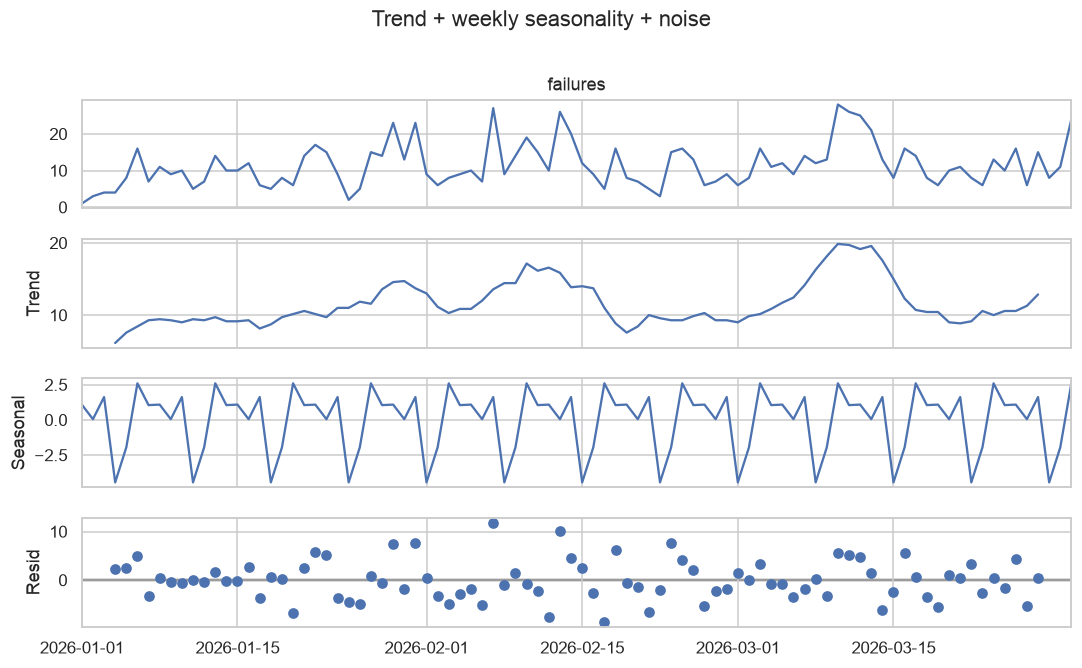

ADF test: statistic = -6.18, p-value = 0.0000 → stationary


In [24]:
ts = pd.read_csv("data/daily_counts.csv", parse_dates=["date"]).set_index("date")
ts = ts.asfreq("D")
y = ts["failures"].astype(float)
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
dec = seasonal_decompose(y, model="additive", period=7)
fig = dec.plot(); fig.set_size_inches(10, 6); fig.suptitle("Trend + weekly seasonality + noise", y=1.01)
plt.tight_layout(); plt.savefig("figures/08_decomposition.png"); plt.show()
adf = adfuller(y)
print(f"ADF test: statistic = {adf[0]:.2f}, p-value = {adf[1]:.4f} → {'stationary' if adf[1] < .05 else 'non-stationary (difference it)'}")

In [25]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

h = 14
y_tr_ts, y_te_ts = y[:-h], y[-h:]

fc = {
    "Naive (mean of last 7 days)": pd.Series(y_tr_ts[-7:].mean(), index=y_te_ts.index),
    "ARIMA(1,1,1)": ARIMA(y_tr_ts, order=(1, 1, 1)).fit().forecast(h),
    "SARIMA(1,0,1)(1,0,1,7)": SARIMAX(y_tr_ts, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7), trend="c").fit(disp=0).forecast(h),
    "Simple exp. smoothing": SimpleExpSmoothing(y_tr_ts, initialization_method="estimated").fit().forecast(h),
    "Holt-Winters (trend + weekly)": ExponentialSmoothing(y_tr_ts, trend="add", seasonal="add", seasonal_periods=7, initialization_method="estimated").fit().forecast(h),
}
ts_res = pd.DataFrame({k: {"RMSE": np.sqrt(mean_squared_error(y_te_ts, v)), "MAE": mean_absolute_error(y_te_ts, v)} for k, v in fc.items()}).T
ts_res.sort_values("RMSE")

/Users/spookymac/Downloads/data_Q1_2026/mini_project/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting seasonal autoregressive Using zeros as starting parameters.
  start_params = self.start_params


,RMSE,MAE
"SARIMA(1,0,1)(1,0,1,7)",5.422,4.368
"ARIMA(1,1,1)",5.779,5.074
Holt-Winters (trend + weekly),6.478,5.854
Simple exp. smoothing,6.548,5.821
Naive (mean of last 7 days),8.233,7.633


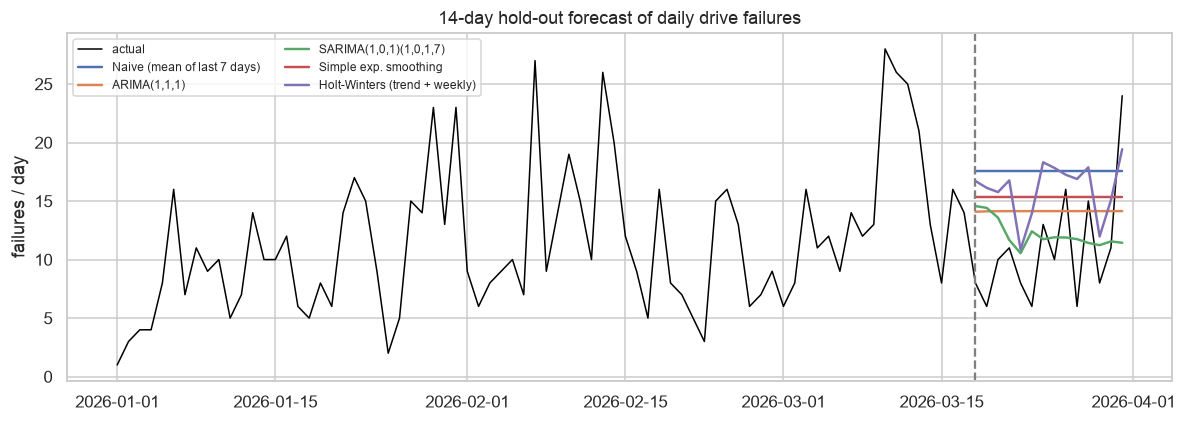

In [26]:
plt.figure(figsize=(11, 4))
plt.plot(y, color="black", lw=1, label="actual")
for k, v in fc.items(): plt.plot(v, lw=1.6, label=k)
plt.axvline(y_te_ts.index[0], ls="--", color="gray"); plt.ylabel("failures / day"); plt.legend(fontsize=8, ncol=2)
plt.title("14-day hold-out forecast of daily drive failures"); plt.tight_layout(); plt.savefig("figures/09_forecast.png"); plt.show()

In [27]:
# Refit the best model on all data and forecast the next 14 days → spare-drive planning
best_name = ts_res["RMSE"].idxmin(); print("best model:", best_name)
final = SARIMAX(y, order=(1, 0, 1), seasonal_order=(1, 0, 1, 7), trend="c").fit(disp=0, maxiter=500)
f = final.get_forecast(14); ci = f.conf_int(alpha=0.10)
week1, week2 = f.predicted_mean[:7].sum(), f.predicted_mean[7:].sum()
print(f"Expected failures next week: {week1:.0f}; the week after: {week2:.0f}")
print(f"Spare drives to stock for 2 weeks (90% upper bound): {ci.iloc[:, 1].clip(lower=0).sum():.0f}")

best model: SARIMA(1,0,1)(1,0,1,7)


Expected failures next week: 91; the week after: 81
Spare drives to stock for 2 weeks (90% upper bound): 305


*Note on the stock-price topic:* the same ARIMA / exponential-smoothing toolkit is used for stock prices; the
difference is that prices are usually a random walk (needing `d = 1`), whereas daily failure counts here fluctuate
around a stable level.

## 13. From prediction to prevention — the early-warning system

### 13.1 How much warning do we get?
For each **failed drive in the test set**, find the first day the logistic model's risk score crossed the alert
threshold. The gap to the actual failure is the **lead time** the operator has to act.

270 failed drives in test set
warned ≥1 day before failure : 102 (38%)
median warning lead time     : 28 days
healthy drives ever flagged  : 0.6%  (false alarms)


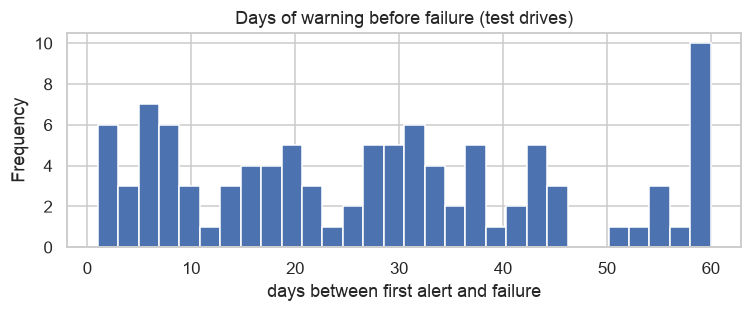

In [28]:
test_all = df[df.serial_number.isin(test.serial_number)].copy()
test_all["risk"] = logit.predict_proba(test_all[features].astype(float))[:, 1]
failed_test = test_all[test_all.failure_date.notna()]
first_alert = failed_test[failed_test.risk >= best_t].groupby("serial_number")["days_to_failure"].max()
n_failed = failed_test.serial_number.nunique()
caught = first_alert[first_alert >= 1]
print(f"{n_failed} failed drives in test set")
print(f"warned ≥1 day before failure : {len(caught)} ({len(caught)/n_failed:.0%})")
print(f"median warning lead time     : {caught.median():.0f} days")
healthy_alert = test_all[test_all.failure_date.isna()].groupby("serial_number")["risk"].max().ge(best_t).mean()
print(f"healthy drives ever flagged  : {healthy_alert:.1%}  (false alarms)")
caught.clip(upper=60).plot.hist(bins=30, figsize=(7, 3), title="Days of warning before failure (test drives)")
plt.xlabel("days between first alert and failure"); plt.tight_layout(); plt.savefig("figures/10_lead_time.png"); plt.show()

### 13.2 Prescriptive layer — recommended mitigation per drive

Each alert carries the **reason** (which SMART signal is abnormal) and a **concrete action**. The rules map each
failure mechanism to the standard fix:

| signal | likely cause | recommended action |
|---|---|---|
| risk ≥ 0.99 | imminent failure | **Evacuate data now** and hot-swap a spare |
| risk ≥ threshold | degrading | Verify backups / RAID, schedule replacement this week |
| bad sectors pending or growing | disk surface deteriorating | Run an extended self-test; replace if still growing |
| CRC errors / command timeouts | cable, backplane or power — *not* the disk | Reseat or replace the cable, check the power supply |
| temperature > 45 °C | cooling | Check fans and airflow in that chassis |

In [29]:
def recommend(r, thr=best_t):
    acts = []
    if r.risk >= 0.99:  acts.append("CRITICAL: evacuate data now & hot-swap drive")
    elif r.risk >= thr: acts.append("WARNING: verify backups/RAID, schedule replacement within 7 days")
    if r.pending_sectors > 0 or r.bad_sector_growth_7d > 0: acts.append("bad sectors: run extended self-test, replace if growing")
    if r.crc_errors > 0 or r.command_timeout_flag: acts.append("check cable/backplane/power")
    if r.temperature_c > 45:         acts.append("improve cooling")
    return "; ".join(acts) or "OK – keep monitoring"

# Score every sampled drive on the LAST day of the quarter (the "today" view an operator would see)
today = df[df.date == df.date.max()].copy()
today["risk"] = logit.predict_proba(today[features].astype(float))[:, 1]
today["tier"] = mlogit.predict(today[features].astype(float))
today["action"] = today.apply(recommend, axis=1)
alerts = today[today.risk >= best_t].sort_values("risk", ascending=False)
print(f"{len(alerts)} of {len(today):,} drives flagged today")
alerts[["serial_number", "model", "age_years", "reallocated_sectors", "pending_sectors", "bad_sector_growth_7d",
        "risk", "tier", "action"]].head(15)

34 of 10,314 drives flagged today


,serial_number,model,age_years,reallocated_sectors,pending_sectors,bad_sector_growth_7d,risk,tier,action
785293,ZL2CV1VC,ST14000NM001G,4.830,"4,640.000","293,648.000","561,248.000",1.000,2,CRITICAL: evacuate data now & hot-swap drive; ...
872902,ZLW0G69V,ST12000NM001G,5.789,"7,496.000","6,928.000","20,400.000",0.996,2,CRITICAL: evacuate data now & hot-swap drive; ...
148010,2AGM5X0Y,HGST HUH721212ALN604,6.884,14.000,"1,805.000","1,877.000",0.996,2,CRITICAL: evacuate data now & hot-swap drive; ...
774031,ZL23X50P,ST16000NM001G,5.057,"27,920.000","8,168.000",32.000,0.995,2,CRITICAL: evacuate data now & hot-swap drive; ...
527872,93M0A03MV4MJ,TOSHIBA MG10ACA20TE,1.708,184.000,"1,350.000","2,791.000",0.995,2,CRITICAL: evacuate data now & hot-swap drive; ...
707136,ZHZ3SFC9,ST14000NM0138,5.287,"6,024.000",96.000,424.000,0.994,2,CRITICAL: evacuate data now & hot-swap drive; ...
506705,8DHZAW7H,HGST HUH721212ALE604,4.597,0.000,"14,152.000",176.000,0.992,2,CRITICAL: evacuate data now & hot-swap drive; ...
552870,AAHMX1DH,HGST HUH721212ALN604,6.884,182.000,774.000,412.000,0.992,2,CRITICAL: evacuate data now & hot-swap drive; ...
763583,ZL22YS77,ST16000NM001G,5.056,"1,304.000",96.000,"1,312.000",0.991,2,CRITICAL: evacuate data now & hot-swap drive; ...
648818,ZA145EFE,ST8000NM0055,0.107,"10,640.000",104.000,"4,224.000",0.989,2,"WARNING: verify backups/RAID, schedule replace..."


In [30]:
alerts.to_csv("early_warning_alerts.csv", index=False)
print("saved early_warning_alerts.csv")

saved early_warning_alerts.csv


## 14. Conclusions

1. **SMART sector-error counters are the early-warning signals.** Having *any* critical error (SMART 5/187/197/198)
   doubles the odds of failing within 7 days (OR ≈ 2.1); pending sectors, bad-sector *growth over the last week* and
   reported-uncorrectable errors add to it. Temperature and CRC (cable) errors carry almost no failure signal and were
   removed by feature selection. Larger-capacity drive families are riskier (OR ≈ 2.0 per SD of capacity).
2. **The classifiers detect real risk, but failure is rare.** Logistic regression, LDA and QDA all reach ROC-AUC ≈ 0.87
   and F1 ≈ 0.23–0.24 on drives they never saw. F1 looks low only because positives are 0.7 % of rows: a precision of
   22 % means an alert is ~30× more likely to precede a failure than a random drive-day. Logistic regression has the
   best F1 and is fully explainable, so it drives the alert system; QDA trades precision for recall.
3. **At drive level the warning is early and cheap.** 38 % of test drives that failed were flagged at least a day
   before — with a **median of ~4 weeks of warning** — while only 0.6 % of healthy drives were ever flagged.
   The remaining failures were sudden (electronics / motor) with clean SMART data: a known ceiling of SMART-based prediction.
4. **Fleet-level models.** The failure counts are over-dispersed (Pearson χ²/df ≈ 10.7), so the **Negative Binomial**
   GLM fits far better than Poisson (AIC 274 vs 501): each extra year of age raises the failure rate ≈ 20 %, each extra TB ≈ 13 %.
   **SARIMA** with weekly seasonality forecasts daily failures best (RMSE 5.4 vs 8.2 for the naive baseline),
   predicting ~90 failures next week → stock ~300 spares for two weeks.
5. **Prescriptive value:** risk score + reason → action (evacuate, replace, self-test, re-cable, cool) turns the
   prediction into prevention; `early_warning_alerts.csv` is the operator's to-do list.

**Limitations & future work:** healthy drives were sub-sampled (3 %), so predicted probabilities are *relative* risk
scores, not true fleet probabilities; only one quarter of data; tree-based models (random forest, gradient boosting)
and survival analysis are natural next steps.